In [1]:
# Persiapan lingkungan Colab (B4_penapisan)
%cd /content
!git clone https://github.com/SuciOktavia02/simuteh-2330511010.git
%cd simuteh-2330511010
!mkdir -p notebook hasil
%cd notebook

/content
Cloning into 'simuteh-2330511010'...
remote: Enumerating objects: 284, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 284 (delta 7), reused 43 (delta 3), pack-reused 237 (from 2)
Receiving objects: 100% (284/284), 75.06 MiB | 26.91 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/simuteh-2330511010
/content/simuteh-2330511010/notebook


In [2]:
# Kode 4.1 Verifikasi konvolusi manual
import sys
sys.path.append("../src")
import time
import cv2, numpy as np, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

def konvolusi(img, k):  # fungsi dari slide P4 (sebenarnya korelasi)
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):  # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"),
                      cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
              }.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=3.477 s, filter2D=0.02415 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.876 s, filter2D=0.00051 s


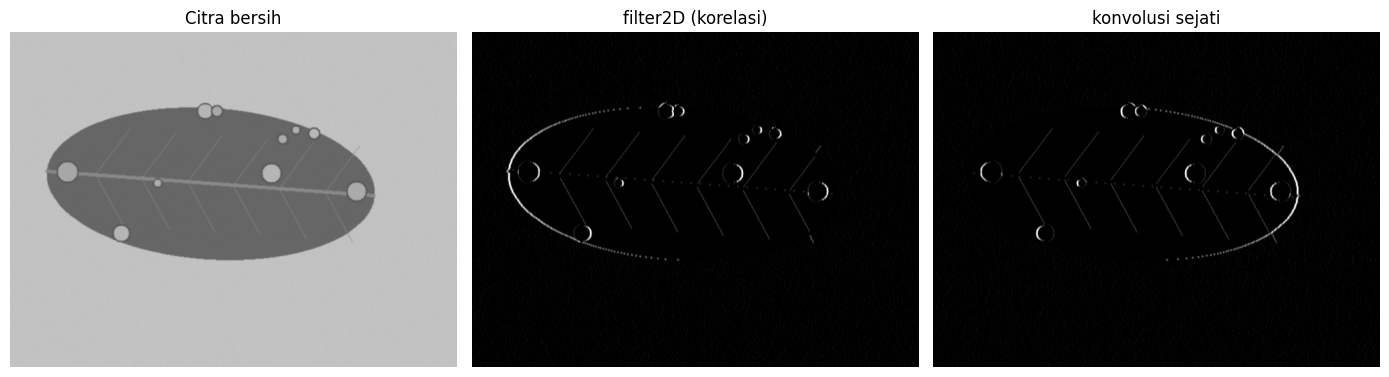

In [3]:
# Kode 4.1b Perbandingan visual: korelasi (filter2D) vs konvolusi sejati
k = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
korelasi = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
sejati = konvolusi_sejati(bersih, k)
tampil([bersih, korelasi, sejati],
       ["Citra bersih", "filter2D (korelasi)", "konvolusi sejati"])
plt.savefig("../hasil/b4_korelasi_vs_konvolusi.png", dpi=150)
plt.show()

   derau  penapis  PSNR_dB  waktu_ms   KB
gauss_10    tanpa    28.11      0.00 4.00
gauss_10 rerata_3    36.80      0.14 6.68
gauss_10 rerata_5    37.38      0.17 6.90
gauss_10  gauss_5    37.60      0.31 6.88
gauss_10 median_3    35.47      0.11 6.55
gauss_10 median_5    38.20      0.91 7.60
gauss_10 median_9    37.97     16.70 8.55
gauss_20    tanpa    22.11      0.00 2.21
gauss_20 rerata_3    31.42      0.15 5.10
gauss_20 rerata_5    34.40      0.17 6.08
gauss_20  gauss_5    32.56      0.30 5.48
gauss_20 median_3    29.73      0.11 4.57
gauss_20 median_5    33.40      0.91 5.97
gauss_20 median_9    35.26     16.96 6.87
gauss_40    tanpa    16.44      0.00 1.18
gauss_40 rerata_3    25.88      0.14 3.30
gauss_40 rerata_5    29.76      0.17 4.71
gauss_40  gauss_5    27.09      0.30 3.71
gauss_40 median_3    23.82      0.11 2.75
gauss_40 median_5    27.81      0.92 4.04
gauss_40 median_9    31.17     18.78 5.21
   sp_4%    tanpa    19.20      0.00 1.68
   sp_4% rerata_3    28.39      0.

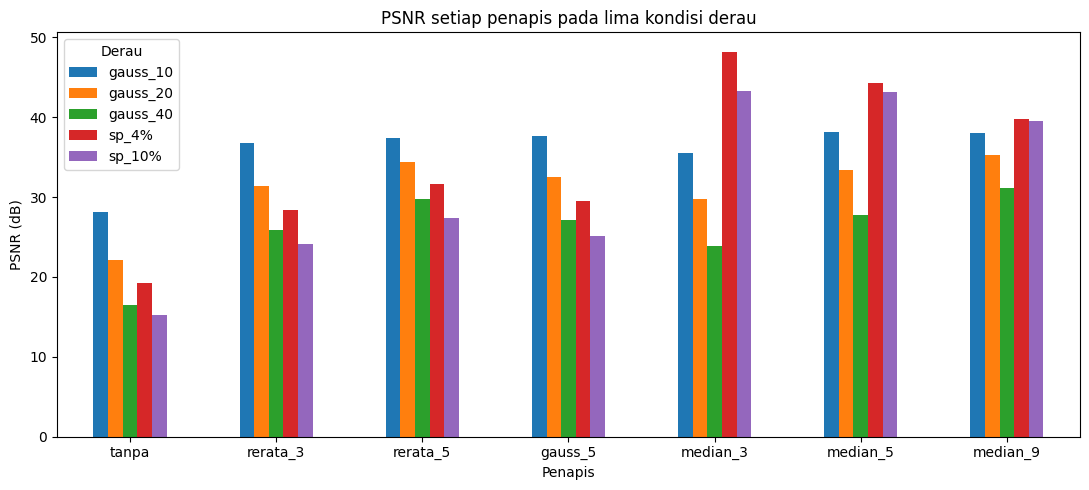

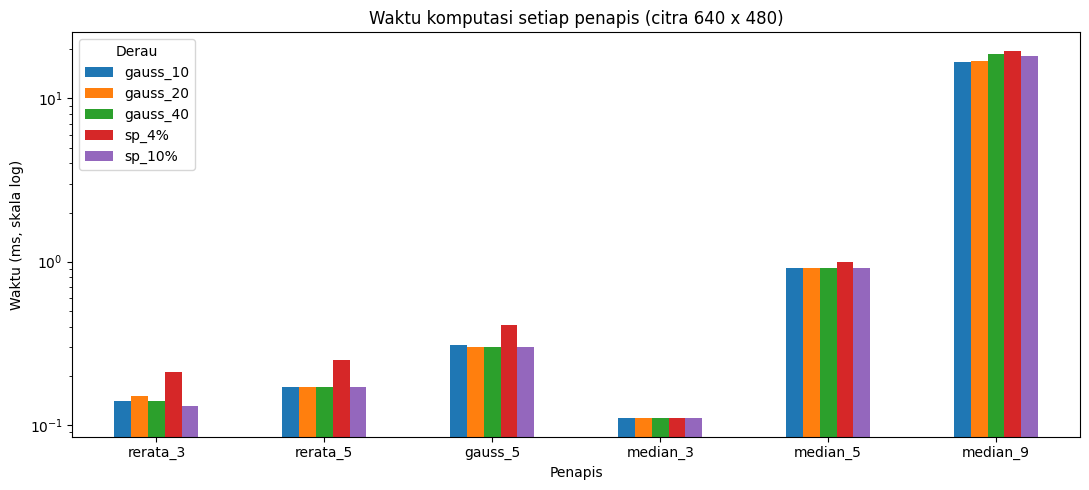

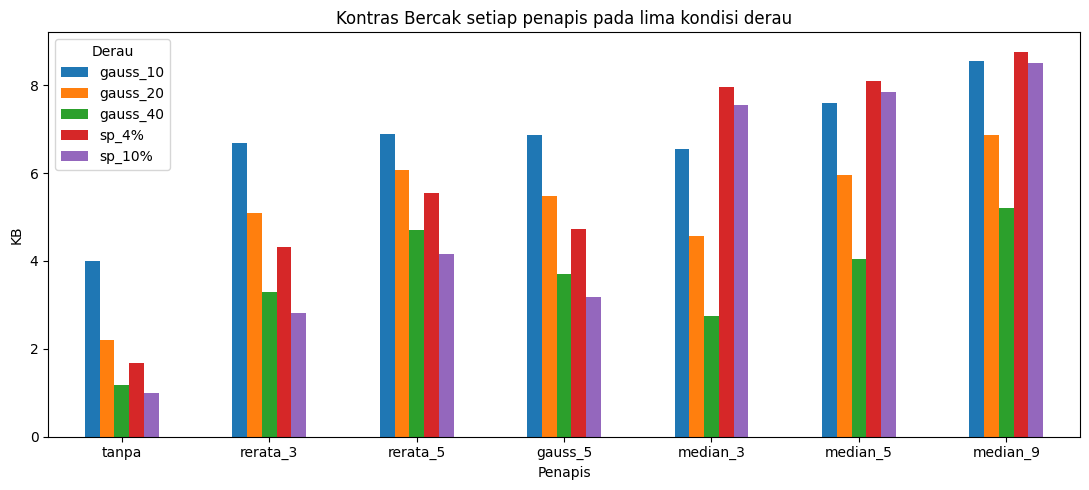

In [4]:
# Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB
import sys
sys.path.append("../src")
import time
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"),
                      cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):  # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}

penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
print(tabel.to_string(index=False))
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

# ---- Tabel 11: Gaussian 20 dan garam-merica 4% ----
urut = ["tanpa", "rerata_3", "rerata_5", "gauss_5",
        "median_3", "median_5", "median_9"]
def ambil(dn, awalan):
    t = tabel[tabel.derau == dn].set_index("penapis").loc[urut]
    return t[["PSNR_dB", "waktu_ms", "KB"]].add_prefix(awalan)
t11 = pd.concat([ambil("gauss_20", "G20_"), ambil("sp_4%", "SP4_")], axis=1)
print("\nTabel 11")
print(t11.to_string())
t11.to_csv("../hasil/b4_tabel11.csv")

# ---- Grafik seluruh hasil ----
kol = ["gauss_10", "gauss_20", "gauss_40", "sp_4%", "sp_10%"]

psnr = tabel.pivot(index="penapis", columns="derau", values="PSNR_dB")
psnr = psnr.loc[urut, kol]
psnr.plot(kind="bar", figsize=(11, 5), rot=0)
plt.ylabel("PSNR (dB)"); plt.xlabel("Penapis")
plt.title("PSNR setiap penapis pada lima kondisi derau")
plt.legend(title="Derau"); plt.tight_layout()
plt.savefig("../hasil/b4_grafik_psnr.png", dpi=150)
plt.show()

waktu = tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau",
                                              values="waktu_ms")
waktu = waktu.loc[urut[1:], kol]
waktu.plot(kind="bar", figsize=(11, 5), rot=0, logy=True)
plt.ylabel("Waktu (ms, skala log)"); plt.xlabel("Penapis")
plt.title("Waktu komputasi setiap penapis (citra 640 x 480)")
plt.legend(title="Derau"); plt.tight_layout()
plt.savefig("../hasil/b4_grafik_waktu.png", dpi=150)
plt.show()

kb = tabel.pivot(index="penapis", columns="derau", values="KB").loc[urut, kol]
kb.plot(kind="bar", figsize=(11, 5), rot=0)
plt.ylabel("KB"); plt.xlabel("Penapis")
plt.title("Kontras Bercak setiap penapis pada lima kondisi derau")
plt.legend(title="Derau"); plt.tight_layout()
plt.savefig("../hasil/b4_grafik_kb.png", dpi=150)
plt.show()

In [5]:
# ===== Langkah 4.4 | Kode 4.3: Pengaruh ukuran kernel median pada bercak kecil (20 citra kelas ringan) =====
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]: # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rm = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rm)
rm.to_csv("../hasil/b4_median_kernel.csv")

           dI    KB
kernel             
1       27.04  4.22
3       27.40  4.34
5       26.16  4.20
9       19.97  3.70
15       6.45  1.77


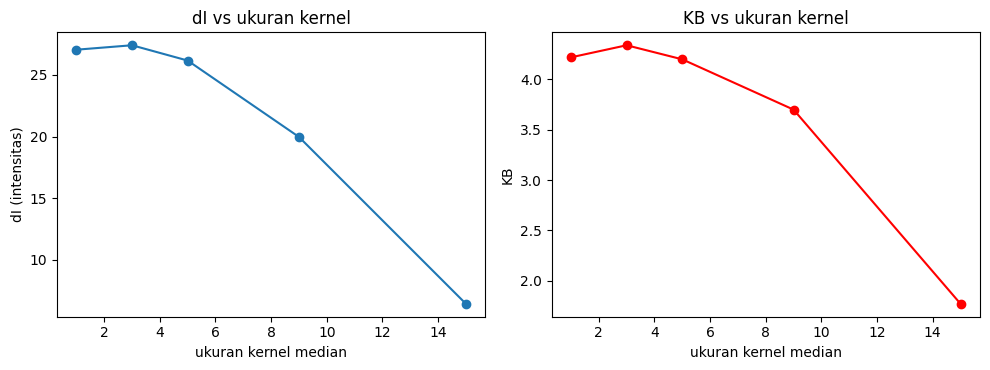

In [6]:
# ===== Langkah 4.4 | Grafik dI dan KB terhadap ukuran kernel median =====
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(rm.index, rm.dI, "o-")
ax[0].set_xlabel("ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)"); ax[0].set_title("dI vs ukuran kernel")
ax[1].plot(rm.index, rm.KB, "o-r")
ax[1].set_xlabel("ukuran kernel median"); ax[1].set_ylabel("KB"); ax[1].set_title("KB vs ukuran kernel")
plt.tight_layout()
plt.savefig("../hasil/b4_di_kb_kernel.png", dpi=110)
plt.show()

Bercak terkecil: teh_021.png | luas (piksel): 149 | pusat: (254, 243)


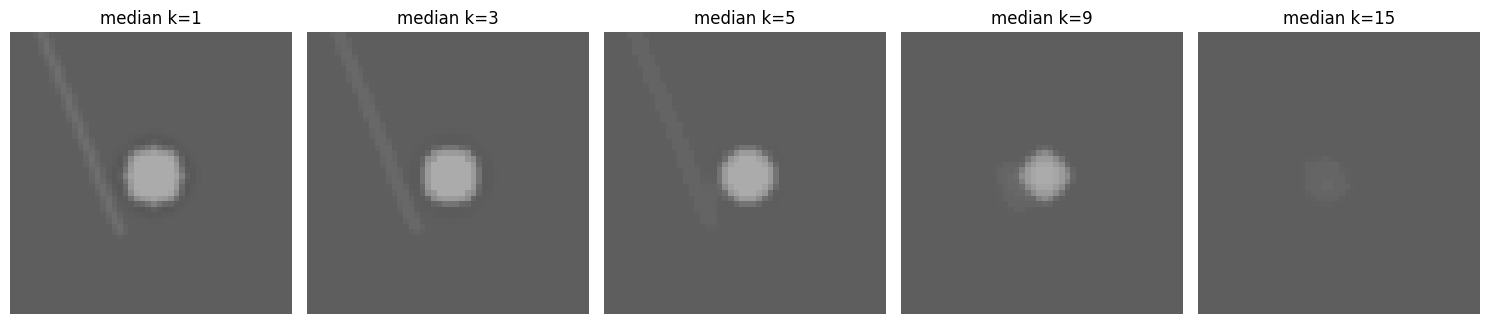

In [7]:
# ===== Langkah 4.4 | Crop satu bercak kecil: efek kernel median 1, 3, 5, 9, 15 =====
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
n, lab, st, cen = cv2.connectedComponentsWithStats(mb2)
i = 1 + int(np.argmin(st[1:, cv2.CC_STAT_AREA]))      # bercak dengan luas terkecil
cx, cy = map(int, cen[i])
print("Bercak terkecil:", nm, "| luas (piksel):", st[i, cv2.CC_STAT_AREA], "| pusat:", (cx, cy))
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a, k in zip(ax, [1, 3, 5, 9, 15]):
    out = g if k == 1 else cv2.medianBlur(g, k)
    a.imshow(out[max(cy-25, 0):cy+25, max(cx-25, 0):cx+25], cmap="gray", vmin=0, vmax=255)
    a.set_title(f"median k={k}"); a.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b4_crop_bercak.png", dpi=110)
plt.show()

In [8]:
# ===== Langkah 4.5 | Kode 4.4: Urutan meredam derau dan menajamkan =====
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)
noisy = derau["gauss_20"]
latar = md == 0 # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)) # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy)) # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.37 sigma_latar=8.1 | redam->tajam PSNR=30.19 sigma_latar=8.3
Median: tajam->redam PSNR=30.13 sigma_latar=8.2 | redam->tajam PSNR=31.09 sigma_latar=7.3


In [9]:
# ===== Langkah 4.6 | Kerjakan sendiri: PSNR 12 citra kondisi normal, sebelum dan sesudah penapisan =====
normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)][:12]   # teh_001, 006, 011, ... (12 citra)
print(normal)

kandidat = {"tanpa": lambda x: x,
            "rerata_3": lambda x: cv2.blur(x, (3, 3)),
            "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
            "median_3": lambda x: cv2.medianBlur(x, 3)}

baris = []
for nm in normal:
    citra = baca(f"../data/sintetis/citra/{nm}")     # citra berderau sensor bawaan
    bersih_c = baca(f"../data/sintetis/bersih/{nm}")  # pasangan tanpa gangguan (acuan)
    r = {"nama": nm}
    for kn, f in kandidat.items():
        r[kn] = cv2.PSNR(bersih_c, f(citra))          # PSNR terhadap citra bersih
    baris.append(r)

t46 = pd.DataFrame(baris).round(2)
print(t46.to_string(index=False))
print("Rerata PSNR (dB):")
print(t46.drop(columns="nama").mean().round(2))
t46.to_csv("../hasil/b4_psnr_12_normal.csv", index=False)

['teh_001.png', 'teh_006.png', 'teh_011.png', 'teh_016.png', 'teh_021.png', 'teh_026.png', 'teh_031.png', 'teh_036.png', 'teh_041.png', 'teh_046.png', 'teh_051.png', 'teh_056.png']
       nama  tanpa  rerata_3  gauss_5  median_3
teh_001.png  27.50     36.38    37.26     34.98
teh_006.png  31.84     39.50    39.84     38.96
teh_011.png  32.16     39.97    40.39     39.23
teh_016.png  30.22     38.49    39.08     37.48
teh_021.png  32.15     39.79    40.11     39.23
teh_026.png  25.54     34.65    35.67     33.09
teh_031.png  29.88     38.08    38.63     37.12
teh_036.png  26.13     35.13    36.08     33.64
teh_041.png  27.06     35.84    36.66     34.44
teh_046.png  26.65     35.35    36.11     34.04
teh_051.png  26.45     35.25    36.08     33.87
teh_056.png  25.32     34.28    35.19     32.80
Rerata PSNR (dB):
tanpa       28.41
rerata_3    36.89
gauss_5     37.59
median_3    35.74
dtype: float64


In [10]:
# ===== Unduh folder hasil B4 sebagai ZIP =====
%cd /content
!zip -rq hasil_B4.zip simuteh-2330511010/hasil
from google.colab import files
files.download("hasil_B4.zip")
%cd /content/simuteh-2330511010/notebook

/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/content/simuteh-2330511010/notebook
